In [1]:
%pip install lightkurve numpy pandas

  Using cached lightkurve-2.6.0-py3-none-any.whl.metadata (6.5 kB)
Using cached lightkurve-2.6.0-py3-none-any.whl (261 kB)
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 25.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import lightkurve as lk
import numpy as np
import pandas as pd


def load_and_clean_lightcurve(target: str, mission: str = "Kepler", sigma: float = 5.0, window_length: int = 401):
    """
    دانلود، حذف مقادیر NaN، حذف نقاط پرت، نرمال‌سازی و صاف کردن روند کند منحنی نور
    """
    search = lk.search_lightcurve(target, mission=mission)
    if len(search) == 0:
        raise ValueError(f"منحنی نوری برای {target} در ماموریت {mission} پیدا نشد.")

    collection = search.download_all()
    lc = collection.stitch() if len(collection) > 1 else collection[0]

    lc_clean = lc.remove_nans().remove_outliers(sigma=sigma).normalize()
    lc_flat = lc_clean.flatten(window_length=window_length)
    return lc_flat


def fold_and_extract_window(lc_flat, period: float, epoch_time: float, phase_half_width: float = 0.05, n_bins: int = 100):
    """
    هم‌فازسازی منحنی نور حول دوره تناوب و زمان میانه گذر، و باینینگ پنجره گذر به طول ثابت
    """
    folded = lc_flat.fold(period=period, epoch_time=epoch_time)
    phase = folded.phase.value
    flux = folded.flux.value

    mask = np.abs(phase) <= phase_half_width
    win_phase = phase[mask]
    win_flux = flux[mask]

    if len(win_phase) < 10:
        return None, None

    order = np.argsort(win_phase)
    win_phase = win_phase[order]
    win_flux = win_flux[order]

    bins = np.linspace(-phase_half_width, phase_half_width, n_bins + 1)
    bin_centers = 0.5 * (bins[:-1] + bins[1:])
    binned_flux = np.empty(n_bins, dtype=float)

    for i in range(n_bins):
        in_bin = (win_phase >= bins[i]) & (win_phase < bins[i + 1])
        if np.any(in_bin):
            binned_flux[i] = np.nanmedian(win_flux[in_bin])
        else:
            binned_flux[i] = np.nan

    # پر کردن جای خالی احتمالی با میانه پنجره
    fallback_median = np.nanmedian(win_flux)
    binned_flux = np.where(np.isnan(binned_flux), fallback_median, binned_flux)
    return bin_centers, binned_flux


def extract_transit_features(bin_centers: np.ndarray, binned_flux: np.ndarray) -> dict:
    """
    استخراج ویژگی‌های هندسی و آماری ساده از منحنی هم‌فازشده حول گذر
    """
    # حول مرکز فاز (0) یک پنجره مرکزی و دو حاشیه چپ و راست در نظر می‌گیریم
    center_mask = np.abs(bin_centers) <= 0.015
    side_mask = (np.abs(bin_centers) > 0.025) & (np.abs(bin_centers) <= 0.05)

    baseline = np.median(binned_flux[side_mask]) if np.any(side_mask) else np.median(binned_flux)
    min_flux = np.min(binned_flux[center_mask]) if np.any(center_mask) else np.min(binned_flux)

    transit_depth = max(0.0, baseline - min_flux)
    flux_std = np.std(binned_flux)
    snr_proxy = transit_depth / (flux_std + 1e-8)

    left_mask = (bin_centers >= -0.04) & (bin_centers < -0.005)
    right_mask = (bin_centers > 0.005) & (bin_centers <= 0.04)
    left_mean = np.mean(binned_flux[left_mask]) if np.any(left_mask) else baseline
    right_mean = np.mean(binned_flux[right_mask]) if np.any(right_mask) else baseline
    asymmetry = abs(left_mean - right_mean)

    return {
        "baseline_flux": float(baseline),
        "min_flux": float(min_flux),
        "transit_depth": float(transit_depth),
        "flux_std": float(flux_std),
        "snr_proxy": float(snr_proxy),
        "asymmetry": float(asymmetry),
    }

c:\Users\island\AppData\Local\Programs\Python\Python312\Lib\site-packages\lightkurve\prf\__init__.py:7: UserWarning: Warning: the tpfmodel submodule is not available without oktopus installed, which requires a current version of autograd. See #1452 for details.
  warnings.warn(


تعداد فایل‌های یافت‌شده: 50


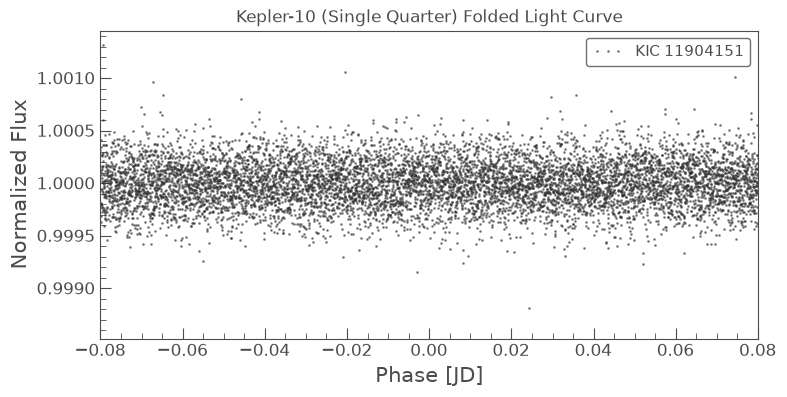

In [4]:
import lightkurve as lk
import matplotlib.pyplot as plt

search = lk.search_lightcurve("Kepler-10", mission="Kepler")
print("تعداد فایل‌های یافت‌شده:", len(search))

# دانلود فقط یک فایل (مثلاً فایل اول) برای تست سریع و کم‌حجم
lc = search[0].download()

lc_clean = lc.remove_nans().remove_outliers(sigma=5).normalize()
lc_flat = lc_clean.flatten(window_length=401)

period = 0.837495
epoch = 132.04
lc_folded = lc_flat.fold(period=period, epoch_time=epoch)

ax = lc_folded.plot(linewidth=0, marker=".", markersize=2, alpha=0.5)
ax.set_xlim(-0.08, 0.08)
plt.title("Kepler-10 (Single Quarter) Folded Light Curve")
plt.show()

In [7]:
# نمونه اولیه برای تست خط لوله بدون نیاز به کوئری TAP
# فرمت: (kepid, kepoi_name, period_days, epoch_bkjd, label)
sample_targets = [
    (11904151, "K00072.01", 0.837495, 132.04, 1),
    # سایر نمونه‌های کپلر را در صورت نیاز اینجا اضافه کنید
]

rows = []
for kepid, kepoi_name, period, epoch, label in sample_targets:
  target_str = f"KIC {kepid}"
  try:
    s = lk.search_lightcurve(target_str, mission="Kepler")
    if len(s) == 0:
      continue
    lc = s[0].download()
    lc_clean = lc.remove_nans().remove_outliers(sigma=5).normalize()
    lc_flat = lc_clean.flatten(window_length=401)

    bin_centers, binned_flux = fold_and_extract_window(
        lc_flat, period=period, epoch_time=epoch
    )
    if binned_flux is None:
      continue

    feats = extract_transit_features(bin_centers, binned_flux)
    feats["kepid"] = kepid
    feats["kepoi_name"] = kepoi_name
    feats["label"] = label
    rows.append(feats)
  except Exception as e:
    print(f"خطا در پردازش {target_str}: {e}")

dataset_df = pd.DataFrame(rows)
display(dataset_df)

,baseline_flux,min_flux,transit_depth,flux_std,snr_proxy,asymmetry,kepid,kepoi_name,label
0,0.999998,0.999942,0.000057,0.000034,1.680889,0.000001,11904151,K00072.01,1


In [10]:
def plot_binned_transits(targets_info, phase_half_width=0.05, n_bins=100):
  plt.figure(figsize=(8, 4.5))
  for kepid, name, period, epoch, label in targets_info:
    s = lk.search_lightcurve(f"KIC {kepid}", mission="Kepler")
    if len(s) == 0:
      continue
    lc = s[0].download().remove_nans().remove_outliers(sigma=5).normalize()
    lc_flat = lc.flatten(window_length=401)
    bins_x, bins_y = fold_and_extract_window(
        lc_flat, period=period, epoch_time=epoch, phase_half_width=phase_half_width, n_bins=n_bins
    )
    if bins_x is not None:
      tag = "CONFIRMED" if label == 1 else "FALSE POSITIVE"
      plt.plot(bins_x, bins_y, label=f"{name} ({tag})", alpha=0.85)

  plt.axvline(0, linestyle="--", alpha=0.6, label="Transit Center")
  plt.xlabel("Orbital Phase")
  plt.ylabel("Binned Normalized Flux")
  plt.title("Binned Transit Profiles Across Kepler Targets")
  plt.legend()
  plt.tight_layout()
  plt.show()

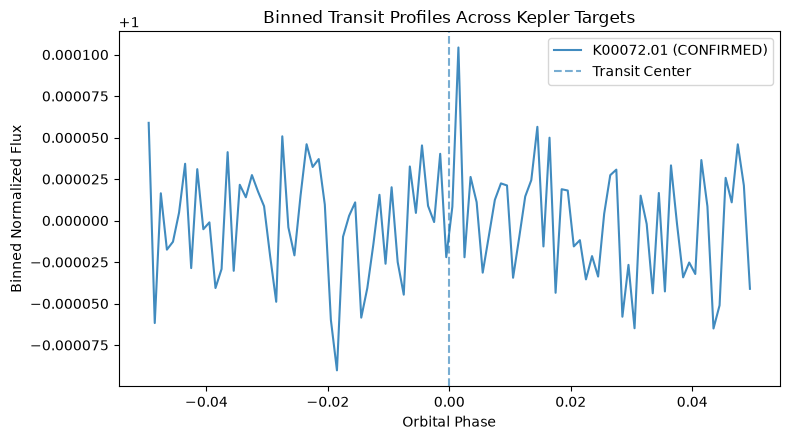

In [11]:
plot_binned_transits(sample_targets)

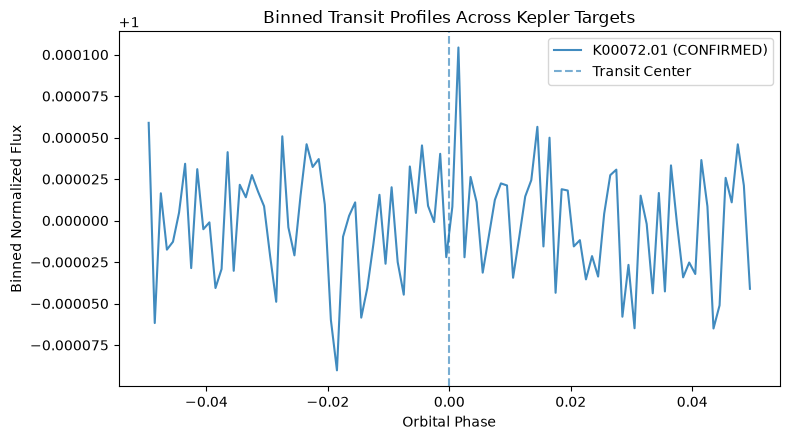

In [12]:
sample_targets = [
    (11904151, "K00072.01", 0.837495, 132.04, 1),
    # نمونه‌های اضافی را با فرمت (kepid, kepoi_name, period_days, epoch_bkjd, label) بیفزایید
]

plot_binned_transits(sample_targets, phase_half_width=0.05, n_bins=100)